## Cosmic Web - JAX - Fusion - SOLUTION

[JAX](https://docs.jax.dev/en/latest/) runs the same array code under `jax.jit`: the *traced graph* model. JAX *traces* the function once per input shape, recording every operation on *tracers* (placeholders that carry a shape and a dtype), and hands the trace to XLA, its compiler, which *fuses* neighbouring operations into one kernel where it can. In this notebook we read what the compiler decided and what a new shape costs.

**SOLUTION**

### Table of Contents

1. [Setup](#1-setup)
2. [Stencil](#2-stencil)
3. [Timing](#3-timing)
4. [Fusion](#4-fusion)
5. [Static shapes](#5-static-shapes)
6. [Launch count](#6-launch-count)
7. [Scatter](#7-scatter)
8. [Limitations and recap](#8-limitations-and-recap)

---

### 1. Setup

By default JAX reserves most of the device memory at its first operation. The `os.environ` line turns that off, so we have some reserve memory to run a profiler probe.

---

**Quick Docs**

- `XLA_PYTHON_CLIENT_PREALLOCATE=false`: allocate on demand instead of reserving the device; set before `import jax`.
- `jnp.asarray(a)`: a JAX array that borrows the CuPy array's buffer: keep the CuPy array alive.

In [1]:
import os
os.environ.setdefault('XLA_PYTHON_CLIENT_PREALLOCATE', 'false')

from functools import partial

import numpy as np
import jax
import jax.numpy as jnp

import cosmic_core as cw

N, K = cw.setup('jax', f'jax {jax.__version__} on {jax.devices()}')
q_dev = cw.by_size(lambda n: jnp.asarray(cw.field(n)))

N = 512^3, K = 128: 512 MiB of int32 on NVIDIA GeForce RTX 4080 SUPER; jax 0.11.1 on [CudaDevice(id=0)]


### 2. Stencil

The stencil is the CuPy code with `cp` replaced by `jnp`. Every shape must be known when XLA compiles, the histogram's included.

---

**Quick Docs**

- `partial(jax.jit, static_argnames=('K',))`: compile with `K` as a *static* argument, fixed at trace time and baked into the executable; a new value triggers a new compile.
- `jnp.bincount(x, length=K)`: counts as int32; `length` fixes the output size.

In [2]:
def ecc_cells_jax(q):
    '''Births of the eight cells each voxel owns, as traced array operations.'''
    ex = jnp.minimum(q, jnp.roll(q, -1, 0))
    ey = jnp.minimum(q, jnp.roll(q, -1, 1))
    ez = jnp.minimum(q, jnp.roll(q, -1, 2))
    fxy = jnp.minimum(ex, jnp.roll(ex, -1, 1))
    fxz = jnp.minimum(ex, jnp.roll(ex, -1, 2))
    fyz = jnp.minimum(ey, jnp.roll(ey, -1, 2))
    c = jnp.minimum(fxy, jnp.roll(fxy, -1, 2))
    return q, (ex, ey, ez), (fxy, fxz, fyz), c


@partial(jax.jit, static_argnames=('K',))
def ecc_hist_jax(q, K):
    '''Signed histogram of births (int32, length K), one compiled executable.'''
    v, (ex, ey, ez), (fxy, fxz, fyz), c = ecc_cells_jax(q)
    bc = lambda a: jnp.bincount(a.ravel(), length=K)
    return bc(v) - bc(ex) - bc(ey) - bc(ez) + bc(fxy) + bc(fxz) + bc(fyz) - bc(c)

`K` is a static argument and `jnp.bincount` takes `length=K`. Why can `length` not be traced? Let's try it:

In [3]:
try:
    jax.jit(lambda a: jnp.bincount(a.ravel()))(q_dev(N))
except Exception as e:
    print(f'jnp.bincount without length= under jit: {type(e).__name__}')
    print('  ' + str(e).splitlines()[0][:160])

jnp.bincount without length= under jit: ConcretizationTypeError
  Abstract tracer value encountered where concrete value is expected: traced array with shape int32[134217728]


- Without `length` the output size would be `x.max() + 1`, a value that depends on the data.
- A tracer carries only a shape and a dtype, and XLA needs every shape before it compiles.

### 3. Timing

JAX dispatches asynchronously: a call returns before the device finishes. The runner therefore calls the compiled function on the prebuilt device array and waits for the result.

---

**Quick Docs**

- `jax.block_until_ready(x)`: wait for every array in `x`; required before stopping any timer.

In [4]:
def run_jax(n):
    hist = jax.block_until_ready(ecc_hist_jax(q_dev(n), K=K))
    return np.asarray(hist, dtype=np.int64)

Now let's make sure it works.

In [5]:
_ = cw.measure('jax', run_jax, N, prepare=q_dev, cold_note='incl. trace and XLA compile')

[jax] N=512^3 K=128 | cold    248.1 ms (incl. trace and XLA compile) | warm    141.6 ms = 0.948 Gvoxel/s | max|Δχ| 0 | Σ 0 | PASS


### 4. Fusion

Two views of one function:

- A *jaxpr* (short for JAX expression) is JAX's internal intermediate representation (IR) of the traced function: its primitives in the order the trace recorded them.
- The compiled text (HLO) shows what XLA made of it: each *fusion* is a group of primitives compiled into one kernel. A *scatter* writes each element to an address given by an index array. `jnp.bincount` compiles to a scatter-add, and XLA fuses the operations that compute its input into the same kernel.

How many fusions and scatters would you expect from eight bincounts?

---

**Quick Docs**

- `jax.make_jaxpr(fn, static_argnums=(1,))(q, K)`: the trace as a jaxpr; `fn.__wrapped__` is the Python function under the jit.
- `ecc_hist_jax.lower(q, K=K).compile()`: the executable; `.as_text()` is the compiled text (HLO), `.memory_analysis()` its memory plan.
- `cw.compile_report(stage, jaxpr, compiled)`: prints the jaxpr's primitives and the executable's fusions, scatters and temporaries; attaches the counts to the stage file.

In [6]:
jaxpr = jax.make_jaxpr(ecc_hist_jax.__wrapped__, static_argnums=(1,))(q_dev(N), K)
compiled = ecc_hist_jax.lower(q_dev(N), K=K).compile()
cw.compile_report('jax', jaxpr, compiled)

jaxpr: 229 lines; primitives: add, broadcast_in_dim, concatenate, convert_element_type, jit, lt, max, min, reshape, scatter-add, select_n, slice, sub
compiled: 15 fusions, 8 scatters; temporaries 2.0 full-size arrays


- The jaxpr lists the NumPy code as primitives: each roll is recorded as a pair of slices and a concatenate, each bincount as a scatter-add.
- XLA fused each roll-and-minimum chain into the kernel that feeds its scatter, so there are far fewer fusions than jaxpr lines.
- The eight scatters stayed separate, one per bincount.
- The executable's temporaries amount to a few full-size arrays: most intermediates stay on chip.

### 5. Static shapes

The executable is specialised to its input shapes, so each new $N$ compiles again.

---

**Quick Docs**

- `jax.clear_caches()`: forget every compiled executable, so the next call compiles.
- `cw.save_sweep(stage, run, first_call=True, prepare=q_dev)`: the sweep with the first call at every size timed too, after `prepare(n)`.
- `cw.plot_compile_share(stage, title, compile_label)`: the first call at every size of the stage's sweep, split into compile and run.

  N=  64^3  first     71.35 ms  warm      0.42 ms    0.621 Gvoxel/s  max|Δχ| 0  Σ 0
  N= 128^3  first     72.67 ms  warm      2.52 ms    0.833 Gvoxel/s  max|Δχ| 0  Σ 0


  N= 256^3  first     75.28 ms  warm     19.36 ms    0.867 Gvoxel/s  max|Δχ| 0  Σ 0


  N= 512^3  first    207.66 ms  warm    141.66 ms    0.947 Gvoxel/s  max|Δχ| 0  Σ 0


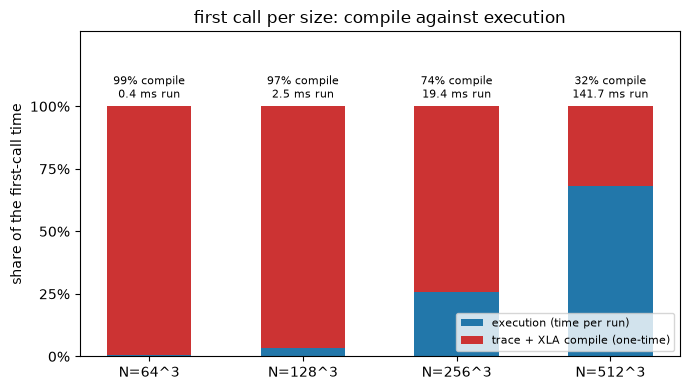

In [7]:
jax.clear_caches()
cw.save_sweep('jax', run_jax, first_call=True, prepare=q_dev)
cw.plot_compile_share('jax', 'first call per size: compile against execution', compile_label='trace + XLA compile (one-time)')

- Every size pays a compile on its first call.
- The compile costs about the same at every size, so at the smallest size it is most of the first call.

### 6. Launch count

One executable launches several kernels, which XLA replays as a CUDA graph. The same probe mechanism as in the CuPy notebook traces one call, with `--cuda-graph-trace=node` so that the kernels inside the graph are listed one by one. How do the launches compare with the fusion count of §4, and which kernels take the time?

In [8]:
trace = cw.trace_call('jax', run_jax, N, [ecc_cells_jax, ecc_hist_jax], state=[q_dev], **cw.JAX_PROBE)
scatter_s = lambda rows: sum(d for _, d, name, kind in rows if kind == 'kernel' and 'scatter' in name)
print(f"scatter kernels: {scatter_s(trace['rows']) * 1e3:.2f} ms of {trace['gpu_busy_s'] * 1e3:.2f} ms GPU busy")

one call at N = 512^3: 15 kernels, 1 memcpys, 0 memsets
scatter kernels: 144.52 ms of 149.41 ms GPU busy


- One kernel per fusion, the eight scatters among them.
- One memcpy remains, the device-to-host copy of the histogram: the device-to-host reads inside `cp.bincount` are gone.
- The scatter kernels take almost the whole of the GPU's time.

### 7. Scatter

Why do the scatters dominate? A scatter-add performs one atomic add per element into one of $K$ addresses. Adds to the same address contend and are serialised.

*Privatise* the histogram: reshape the births into slabs of $S$ voxels and count each slab into its own row of an $(M, K)$ array, so the adds spread over $MK$ addresses. The TODO writes `bc`. The decorator with `S` static and the runner are written.

---

**Quick Docs**

- `a.reshape(-1, S)`: $M = N^3 / S$ rows of $S$ births; a power of two divides every sweep size.
- `jax.vmap(f)(rows)`: `f` applied to every row as one batched operation, here `jnp.bincount(row, length=K)`.
- `jnp.sum(x, axis=0)`: the rows summed into one histogram.

In [9]:
@partial(jax.jit, static_argnames=('K', 'S'))
def ecc_hist_jax_private(q, K, S=2048):
    '''Signed histogram of births (int32, length K): each slab of S voxels counts into its own row first.'''
    v, (ex, ey, ez), (fxy, fxz, fyz), c = ecc_cells_jax(q)
    bc = lambda a: jnp.sum(jax.vmap(lambda row: jnp.bincount(row, length=K))(a.reshape(-1, S)), axis=0)
    return bc(v) - bc(ex) - bc(ey) - bc(ez) + bc(fxy) + bc(fxz) + bc(fyz) - bc(c)


def run_jax_private(n):
    return np.asarray(jax.block_until_ready(ecc_hist_jax_private(q_dev(n), K=K)), dtype=np.int64)

Now let's make sure it works.

In [10]:
_ = cw.measure('jax_private', run_jax_private, N, prepare=q_dev, cold_note='incl. trace and XLA compile')

trace_private = cw.trace_call('jax_private', run_jax_private, N, [ecc_cells_jax, ecc_hist_jax_private], state=[q_dev], **cw.JAX_PROBE)
print(f"scatter kernels: {scatter_s(trace['rows']) * 1e3:.2f} ms before, {scatter_s(trace_private['rows']) * 1e3:.2f} ms after")
cw.save_sweep('jax_private', run_jax_private)

[jax_private] N=512^3 K=128 | cold    134.6 ms (incl. trace and XLA compile) | warm     16.3 ms = 8.227 Gvoxel/s | max|Δχ| 0 | Σ 0 | PASS


one call at N = 512^3: 28 kernels, 1 memcpys, 0 memsets
scatter kernels: 144.52 ms before, 11.72 ms after
  N=  64^3  warm      0.20 ms    1.330 Gvoxel/s  max|Δχ| 0  Σ 0


  N= 128^3  warm      0.35 ms    5.917 Gvoxel/s  max|Δχ| 0  Σ 0
  N= 256^3  warm      2.03 ms    8.256 Gvoxel/s  max|Δχ| 0  Σ 0


  N= 512^3  warm     15.88 ms    8.452 Gvoxel/s  max|Δχ| 0  Σ 0


- The scatter kernels shrank to a fraction of their time: the same scatter-add now spreads over $MK$ addresses instead of $K$.
- The row sums added a few launches.
- The scatters still take most of the call.

Takeaways:

- XLA fused the roll and minimum chains into the scatters' operands. A scatter ends a fusion: XLA starts a new kernel after it, and its cost is the contention of the atomic adds at each address.
- `length=` and `S` are static because every shape is fixed when the executable is built. A new $N$ requires a recompile.

### 8. Limitations and recap

XLA decides the fusion. We can change it only by rewriting the function. JAX integers are int32 unless x64 mode is enabled, so the gate casts to int64 on the host.

Recap:

- The CuPy code ran under `jax.jit` with `cp` replaced by `jnp` and `K` static. The trace located the cost in the scatters that we could optimise with a reshape.

Next: `93__cosmic_web__cccl__iterators.ipynb` describes the stencil to a library algorithm through iterators.